# Exploratory Data Analysis: Singapore Pilot, FY2023

## 1. Load the Cleaned Dataset

In [1]:
from pathlib import Path
import pandas as pd

# Project folder
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Dataset paths
clean_file = ROOT / "data/processed/orbis_sg_fy2023_clean.parquet"
merged_file = ROOT / "data/interim/orbis_singapore_fy2023_merged.parquet"

# Select available file
if clean_file.exists():
    DATA_FILE = clean_file
    print("Using cleaned dataset")

elif merged_file.exists():
    DATA_FILE = merged_file
    print("WARNING: Using merged dataset, not final cleaned data")

else:
    raise FileNotFoundError("No dataset found. Check your data folders.")

print("File:", DATA_FILE)

df = pd.read_parquet(DATA_FILE)
print("Dataset shape:", df.shape)

df.head()

File: /Users/nicolynetiana_/Documents/GitHub/ds607-singapore-firm-size/data/interim/orbis_singapore_fy2023_merged.parquet
Dataset shape: (48995, 28)


,Company name Latin alphabet,Inactive,Quoted,Branch,OwnData,Woco,Country ISO code,"NACE Rev. 2, core code (4 digits)",Consolidation code,BvD ID number,...,GUO - BvD ID number,ISH - Name,GUO - Name,SH - BvD Independence Indicator,Listing status,Status,Closing date Last avail. yr,Closing date 2023,Closing date 2022,_source_file
0,NVIDIA SINGAPORE PTE LTD,No,No,No,No,No,SG,4652,U1,SG200003831M,...,US943177549,"NVIDIA INTERNATIONAL, INC.",NVIDIA CORPORATION,D,Unlisted,Active,2026-01-31,2024-01-31,2023-01-31,orbis_sg_fy2023_part1.xlsx
1,VITOL ASIA PTE LTD,No,No,No,No,No,SG,4671,U1,SG199001917Z,...,LULB43512,VITOL HOLDING B.V.,VITOL HOLDING II S.A.,D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx
2,CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.,No,No,No,No,No,SG,2620,U1,SG201712311G,...,TW04541302,FOCUS PC ENTERPRISES LIMITED,"HON HAI PRECISION IND. CO., LTD.",D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx
3,WILMAR INTERNATIONAL LIMITED,No,Yes,No,No,Yes,SG,1042,C1,SG199904785Z,...,SG199904785Z,<NA>,WILMAR INTERNATIONAL LIMITED,B+,Listed,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx
4,GOOGLE ASIA PACIFIC PTE. LTD.,No,No,No,No,Yes,SG,6391,U1,SG200817984R,...,SG201932822G,GOOGLE APAC TECHNOLOGY PTE. LTD.,GOOGLE APAC TECHNOLOGY PTE. LTD.,D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx


## 2. Inspect Columns, Data Types, and Recorded Missing Values

In [2]:
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Missing values summary
missing_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

display(missing_summary)

Dataset shape: (48995, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48995 entries, 0 to 48994
Data columns (total 28 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Company name Latin alphabet               48995 non-null  string
 1   Inactive                                  48995 non-null  string
 2   Quoted                                    48995 non-null  string
 3   Branch                                    48995 non-null  string
 4   OwnData                                   48995 non-null  string
 5   Woco                                      48995 non-null  string
 6   Country ISO code                          48995 non-null  string
 7   NACE Rev. 2, core code (4 digits)         48995 non-null  string
 8   Consolidation code                        48995 non-null  string
 9   BvD ID number                             48995 non-null  string
 10  Date of incorporati

,Data Type,Missing Count,Missing (%)
Company name Latin alphabet,string,0,0.00
Inactive,string,0,0.00
Quoted,string,0,0.00
Branch,string,0,0.00
OwnData,string,0,0.00
Woco,string,0,0.00
Country ISO code,string,0,0.00
"NACE Rev. 2, core code (4 digits)",string,0,0.00
Consolidation code,string,0,0.00
BvD ID number,string,0,0.00


## 3. Data availability by listing status

In [3]:
# Rename columns 

df = df.rename(columns={
    "Listing status": "listing_status",
    "Total assets th USD 2023": "assets_th_usd",
    "Operating revenue (Turnover) th USD 2023": "revenue_th_usd",
    "Number of employees 2023": "employees",
    "NACE Rev. 2, core code (4 digits)": "nace4",
    "Consolidation code": "consolidation",
    "Date of incorporation": "incorporation_date",
    "BvD ID number": "firm_id"
})


In [4]:
# 3. Listing Status Verification and Data Availability

import pandas as pd

# 3.1 Check listing status
print("Listing Status Counts:")
display(df["listing_status"].value_counts(dropna=False))

# Check for unexpected listing categories
invalid_status = df[~df["listing_status"].isin(["Listed", "Unlisted"])]

print("Invalid listing status:", len(invalid_status))


# 3.2 Data availability by listing status

variables = ["assets_th_usd", "revenue_th_usd", "employees"]

# Ensure financial variables are numeric
for variable in variables:
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:
        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Total Firms": len(group),
            "Available": group[variable].notna().sum(),
            "Missing": group[variable].isna().sum(),
            "Missing (%)": round(group[variable].isna().mean() * 100, 2)
        })

availability_table = pd.DataFrame(results)

display(availability_table)

Listing Status Counts:


listing_status
Unlisted    48499
Listed        496
Name: count, dtype: Int64

Invalid listing status: 0


,Listing Status,Variable,Total Firms,Available,Missing,Missing (%)
0,Listed,assets_th_usd,496,496,0,0.00
1,Listed,revenue_th_usd,496,493,3,0.60
2,Listed,employees,496,267,229,46.17
3,Unlisted,assets_th_usd,48499,48499,0,0.00
4,Unlisted,revenue_th_usd,48499,48187,312,0.64
5,Unlisted,employees,48499,8,48491,99.98


## 4. Financial Data Quality: Zero, Negative, and Implausibly Small Values

1. Missing values: No financial information is reported.
2. Zero values: The firm reports total assets or revenue equal to zero.
3. Negative values: The reported financial amount is below zero.
4. Implausibly small positive values: The firm reports an unusually small amount, such as total assets below USD 1.

In [5]:
# Convert financial variables to numeric

variables = ["assets_th_usd", "revenue_th_usd", "employees"]

for variable in variables:
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

print(df[variables].dtypes)

assets_th_usd     Float64
revenue_th_usd    Float64
employees           Int64
dtype: object


In [6]:
# Financial Data Quality
variables = ["assets_th_usd", "revenue_th_usd"]
results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:
        x = group[variable]

        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Total Firms": len(x),
            "Missing": x.isna().sum(),
            "Zero": (x == 0).sum(),
            "Negative": (x < 0).sum(),
            "Positive below USD 1": ((x > 0) & (x < 0.001)).sum(),
            "Valid Positive": (x > 0).sum()
        })

quality = pd.DataFrame(results)

display(quality)

,Listing Status,Variable,Total Firms,Missing,Zero,Negative,Positive below USD 1,Valid Positive
0,Listed,assets_th_usd,496,0,0,0,0,496
1,Listed,revenue_th_usd,496,3,2,0,0,491
2,Unlisted,assets_th_usd,48499,0,531,19,218,47949
3,Unlisted,revenue_th_usd,48499,312,10292,56,116,37839


Total assets: All 496 listed firms have positive assets. Among 48,499 unlisted firms, 531 have zero assets, 19 have negative assets, and 218 have positive assets below USD 1.

Operating revenue: Revenue is missing for 3 listed and 312 unlisted firms. There are also 10,292 unlisted firms with zero revenue.

Conclusion: Total assets is a suitable primary size measure after excluding non-positive values from the log-assets analysis. Revenue can be used for robustness analysis.

In [7]:
import numpy as np

# Keep positive and non-missing assets
eda_assets = df.loc[df["assets_th_usd"] > 0].copy()

# natural log of assets
eda_assets["log_assets"] = np.log(
    eda_assets["assets_th_usd"].astype(float)
)

print("Original observations:", len(df))
print("Positive-asset observations:", len(eda_assets))

display(eda_assets.head())

Original observations: 48995
Positive-asset observations: 48445


,Company name Latin alphabet,Inactive,Quoted,Branch,OwnData,Woco,Country ISO code,nace4,consolidation,firm_id,...,ISH - Name,GUO - Name,SH - BvD Independence Indicator,listing_status,Status,Closing date Last avail. yr,Closing date 2023,Closing date 2022,_source_file,log_assets
0,NVIDIA SINGAPORE PTE LTD,No,No,No,No,No,SG,4652,U1,SG200003831M,...,"NVIDIA INTERNATIONAL, INC.",NVIDIA CORPORATION,D,Unlisted,Active,2026-01-31,2024-01-31,2023-01-31,orbis_sg_fy2023_part1.xlsx,15.706914
1,VITOL ASIA PTE LTD,No,No,No,No,No,SG,4671,U1,SG199001917Z,...,VITOL HOLDING B.V.,VITOL HOLDING II S.A.,D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,16.251429
2,CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.,No,No,No,No,No,SG,2620,U1,SG201712311G,...,FOCUS PC ENTERPRISES LIMITED,"HON HAI PRECISION IND. CO., LTD.",D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,16.696920
3,WILMAR INTERNATIONAL LIMITED,No,Yes,No,No,Yes,SG,1042,C1,SG199904785Z,...,<NA>,WILMAR INTERNATIONAL LIMITED,B+,Listed,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,17.939555
4,GOOGLE ASIA PACIFIC PTE. LTD.,No,No,No,No,Yes,SG,6391,U1,SG200817984R,...,GOOGLE APAC TECHNOLOGY PTE. LTD.,GOOGLE APAC TECHNOLOGY PTE. LTD.,D,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,16.526577


## 4.1. Investigate Very Small Positive Financial Values

Count positive assets and revenue below US$1 and inspect their most
common values.

In [8]:
# Values are in thousands of USD:
# 0.001 thousand USD = US$1.

for variable in ["assets_th_usd", "revenue_th_usd"]:
    values = df[variable].astype("float64")

    tiny = values.gt(0) & values.lt(0.001)

    print(f"\n{variable}: positive values below US$1")

    print(
        pd.crosstab(
            df["listing_status"],
            tiny,
        ).rename(columns={
            False: "Other or missing",
            True: "Positive below US$1",
        })
    )

    print("\nMost common tiny values, in thousands of USD:")
    print(values.loc[tiny].value_counts().head(10))


assets_th_usd: positive values below US$1
assets_th_usd   Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48281                  218

Most common tiny values, in thousands of USD:
assets_th_usd
0.000758    93
0.001000    54
0.000738    18
0.000733     8
0.000742     7
0.000751     7
0.000999     6
0.000739     3
0.001000     3
0.000732     3
Name: count, dtype: int64

revenue_th_usd: positive values below US$1
revenue_th_usd  Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48383                  116

Most common tiny values, in thousands of USD:
revenue_th_usd
0.000008    30
0.000010    23
0.000758    11
0.000008     4
0.000007     3
0.001000     3
0.000733     3
0.000010     3
0.000739     3
0.000010     3
Name: count, dtype: int64


## 5. Descriptive Statistics by Listing Status

In [9]:

variables = ["assets_th_usd", "revenue_th_usd"]

results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:

        # Use only positive financial values
        x = group[variable].dropna()
        x = x[x > 0].astype(float)

        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Count": len(x),
            "Mean": x.mean(),
            "Std Dev": x.std(),
            "Minimum": x.min(),
            "P25": x.quantile(0.25),
            "Median": x.median(),
            "P75": x.quantile(0.75),
            "P90": x.quantile(0.90),
            "Maximum": x.max()
        })

summary_table = pd.DataFrame(results)

display(summary_table.round(2))

,Listing Status,Variable,Count,Mean,Std Dev,Minimum,P25,Median,P75,P90,Maximum
0,Listed,assets_th_usd,496,1449629.43,4980913.55,9.94,31417.96,96719.23,565607.18,2801027.37,61808692.0
1,Listed,revenue_th_usd,491,674131.29,4002348.87,4.20,17818.03,61648.72,198372.83,641526.63,67715457.0
2,Unlisted,assets_th_usd,47949,44732.77,607244.11,0.00,154.74,1015.30,7139.32,38747.47,79846617.1
3,Unlisted,revenue_th_usd,37839,64609.06,987442.48,0.00,225.87,1121.48,6265.65,31702.63,83465374.0


### observations

Listed firms have substantially higher median assets and revenue than
unlisted firms in the merged sample. Means greatly exceed medians in both
groups, suggesting strongly right-skewed size distributions.

Employee counts are available for 267 listed firms but only 8 unlisted
firms. Employee-based comparisons would therefore describe a highly
selected subset and will not be treated as a main EDA comparison.

Zero and negative financial values require investigation. These results
are descriptive and precede sample exclusions and matching; they do not
establish that listing causes larger firm size.

## 6. Distribution of Total Assets and Operating Revenue

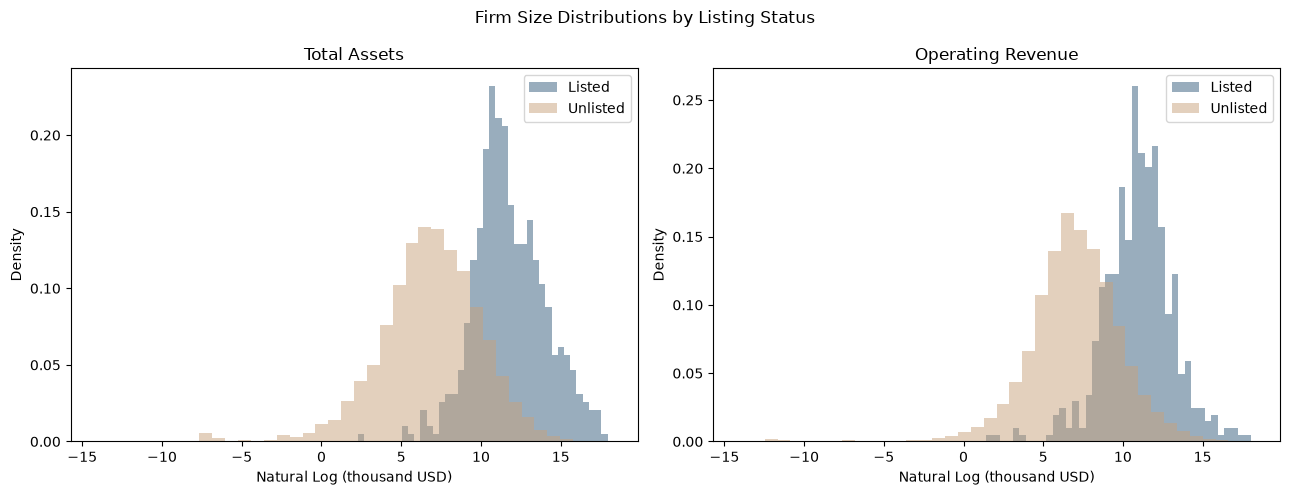

In [10]:
import numpy as np
import matplotlib.pyplot as plt

variables = {
    "assets_th_usd": "Total Assets",
    "revenue_th_usd": "Operating Revenue"
}



COLORS = {
    "Listed": "#355C7D",
    "Unlisted": "#C8A27C"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (variable, title) in zip(axes, variables.items()):

    for status in ["Listed", "Unlisted"]:

        # Select positive values for each group
        x = df.loc[df["listing_status"] == status, variable]
        x = x.dropna()
        x = x[x > 0].astype(float)

        # Natural logarithm
        log_x = np.log(x)

        ax.hist(
            log_x,
            bins=40,
            density=True,
            alpha=0.5,
            color=COLORS[status],
            label=status
        )

    ax.set_title(title)
    ax.set_xlabel("Natural Log (thousand USD)")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Firm Size Distributions by Listing Status")
plt.tight_layout()
plt.show()

The histograms show that listed firms generally have higher total assets and operating revenue than unlisted firms. Both listed-firm distributions are shifted to the right on the natural-log scale, indicating larger typical firm sizes.

Although the distributions overlap, the concentrations of listed and unlisted firms differ substantially. The unlisted distributions also extend further toward very small positive financial values.

These figures use only positive observations, and the comparisons remain unadjusted for differences in industry, firm age and consolidation status.

## 7. Empirical Cumulative Distribution Function (ECDF) of Log Total Assets

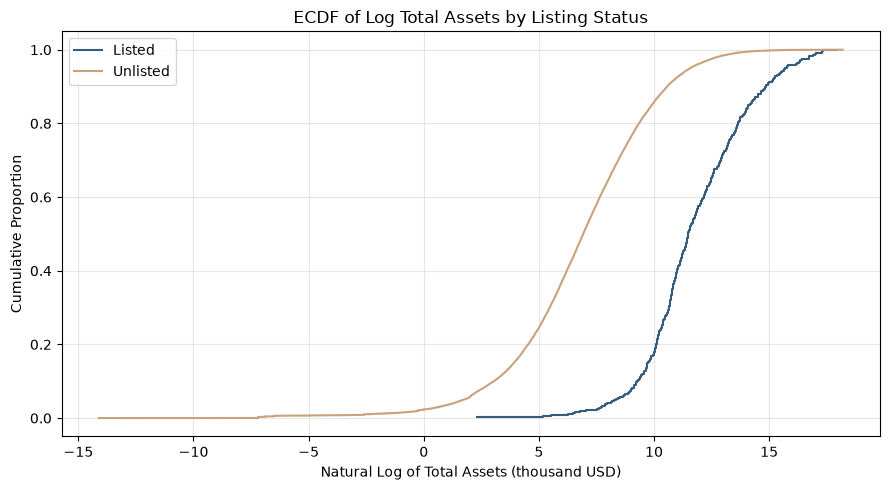

In [11]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for status in ["Listed", "Unlisted"]:

    # Get log assets for each group
    x = eda_assets.loc[
        eda_assets["listing_status"] == status,
        "log_assets"
    ].dropna().to_numpy()

    # Sort values from smallest to largest
    x = np.sort(x)

    # Calculate cumulative proportion
    y = np.arange(1, len(x) + 1) / len(x)

    # Plot ECDF
    plt.step(x, y, where="post", label=status, color=COLORS[status])

plt.title("ECDF of Log Total Assets by Listing Status")
plt.xlabel("Natural Log of Total Assets (thousand USD)")
plt.ylabel("Cumulative Proportion")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: 
In terms of total assets, the Empirical CDF plot clearly shows a move to the right for listed businesses compared to unlisted enterprises. Listed companies are systematically larger over the whole distribution, as evidenced by the fact that they regularly occupy higher percentiles of log-transformed total assets. *Note: These results are only descriptive and do not prove that listing increases company size.

## 8. Boxplot of Log Total Assets by Listing Status

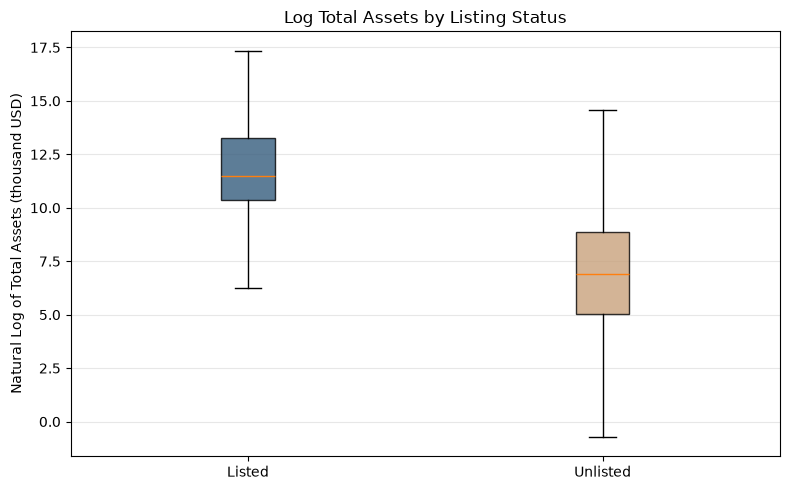

,Listing Status,Count,P25,Median,P75,IQR
0,Listed,496,10.355,11.480,13.246,2.891
1,Unlisted,47949,5.042,6.923,8.873,3.832


In [12]:
import matplotlib.pyplot as plt
import pandas as pd

COLORS = {
    "Listed": "#355C7D",
    "Unlisted": "#C8A27C"
}

# Separate listed and unlisted firms
listed = eda_assets.loc[
    eda_assets["listing_status"] == "Listed",
    "log_assets"
].dropna().astype(float)

unlisted = eda_assets.loc[
    eda_assets["listing_status"] == "Unlisted",
    "log_assets"
].dropna().astype(float)

# Create boxplot
plt.figure(figsize=(8, 5))

bp = plt.boxplot(
    [listed, unlisted],
    tick_labels=["Listed", "Unlisted"],
    patch_artist=True,
    showfliers=False
)

# Apply consistent colors
for patch, status in zip(bp["boxes"], ["Listed", "Unlisted"]):
    patch.set_facecolor(COLORS[status])
    patch.set_alpha(0.8)

# Format graph
plt.title("Log Total Assets by Listing Status")
plt.ylabel("Natural Log of Total Assets (thousand USD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Boxplot summary statistics
results = []

for status, x in [("Listed", listed), ("Unlisted", unlisted)]:
    q1 = x.quantile(0.25)
    median = x.median()
    q3 = x.quantile(0.75)

    results.append({
        "Listing Status": status,
        "Count": len(x),
        "P25": q1,
        "Median": median,
        "P75": q3,
        "IQR": q3 - q1
    })

boxplot_summary = pd.DataFrame(results)

display(boxplot_summary.round(3))

Interpretation: 
The box plot shows that listed enterprises have a much higher median log total asset value and a greater interquartile range (IQR) than unlisted firms. Unlisted businesses display a wider dispersion that extends into significantly lower asset values, whereas listed enterprises display a tightly concentrated, higher median size. *Warning: There is no proof that listing and business size are causally related; this research is descriptive.

## 9. Industry Composition by Listing Status

In [13]:
# Create 2-digit NACE code
df["nace2"] = (
    df["nace4"]
    .astype("string")
    .str.extract(r"(\d{2})", expand=False)
)

# Check industry codes
display(df[["nace4", "nace2"]].head())

print("Missing NACE2:", df["nace2"].isna().sum())


# Industry composition as percentages
industry_table = pd.crosstab(
    df["nace2"],
    df["listing_status"],
    normalize="columns"
) * 100

# Select the 10 most common industries overall
top_industries = df["nace2"].value_counts().head(10).index

industry_top10 = industry_table.loc[top_industries]

display(industry_top10.round(2))

,nace4,nace2
0,4652,46
1,4671,46
2,2620,26
3,1042,10
4,6391,63


Missing NACE2: 0


listing_status,Listed,Unlisted
nace2,,
46,6.25,19.79
70,0.81,11.73
62,2.02,10.43
52,2.82,6.59
68,7.66,5.12
56,2.42,4.26
47,3.63,3.51
71,3.63,3.39
86,2.82,2.55


listing_status,Listed,Unlisted
46 - Wholesale trade,6.25,19.79
70 - Head offices and management consultancy,0.81,11.73
62 - Computer programming and consultancy,2.02,10.43
52 - Warehousing and transport support,2.82,6.59
68 - Real estate,7.66,5.12
56 - Other industry,2.42,4.26
47 - Retail trade,3.63,3.51
71 - Architecture and engineering,3.63,3.39
86 - Other industry,2.82,2.55
82 - Other industry,1.01,2.50


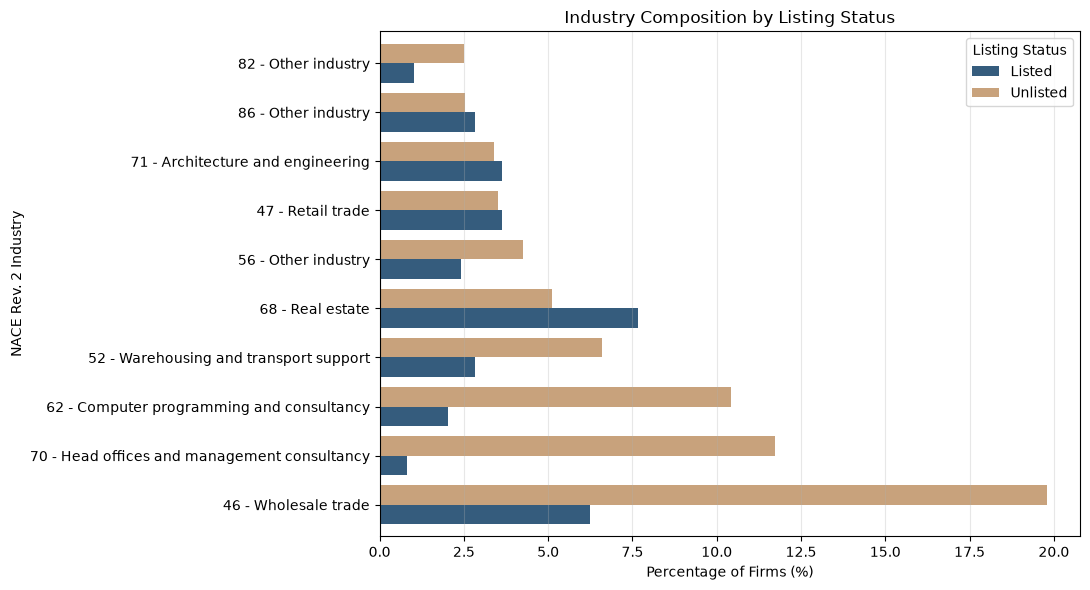

In [14]:
# NACE2 industry labels

nace_labels = {
    "10": "Food manufacturing",
    "26": "Electronics manufacturing",
    "41": "Construction of buildings",
    "46": "Wholesale trade",
    "47": "Retail trade",
    "49": "Land transport",
    "52": "Warehousing and transport support",
    "62": "Computer programming and consultancy",
    "63": "Information service activities",
    "64": "Financial services",
    "68": "Real estate",
    "70": "Head offices and management consultancy",
    "71": "Architecture and engineering",
    "73": "Advertising and market research"
}

industry_top10.index = [
    f"{code} - {nace_labels.get(code, 'Other industry')}"
    for code in industry_top10.index
]

display(industry_top10.round(2))

# Plot industry composition

import matplotlib.pyplot as plt

ax = industry_top10.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.8,
    color=[COLORS["Listed"], COLORS["Unlisted"]]
)

ax.set_title("Industry Composition by Listing Status")
ax.set_xlabel("Percentage of Firms (%)")
ax.set_ylabel("NACE Rev. 2 Industry")
ax.legend(title="Listing Status")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Firm Age and Consolidation Status by Listing Status


We calculate each firm's age in 2023 using:

$$
\text{Firm Age} = 2023 - \text{Incorporation Year}
$$



In [15]:
#  Firm Age

# Extract incorporation year from mixed date formats
df["incorporation_year"] = pd.to_numeric(
    df["incorporation_date"]
    .astype("string")
    .str.extract(r"^(\d{4})", expand=False),
    errors="coerce"
)

#  firm age for FY2023
df["firm_age"] = 2023 - df["incorporation_year"]


# Treat invalid ages as missing
df.loc[df["firm_age"] < 0, "firm_age"] = np.nan

# Create age bands
df["age_band"] = pd.cut(
    df["firm_age"],
    bins=[-1, 4, 9, 19, float("inf")],
    labels=["0–4", "5–9", "10–19", "20+"]
)


display(df[["listing_status", "firm_age", "age_band"]].head())

print("Missing ages:")
print(df.groupby("listing_status")["firm_age"].apply(
    lambda x: x.isna().sum()
))

,listing_status,firm_age,age_band
0,Unlisted,23,20+
1,Unlisted,33,20+
2,Unlisted,6,5–9
3,Listed,24,20+
4,Unlisted,15,10–19


Missing ages:
listing_status
Listed      0
Unlisted    1
Name: firm_age, dtype: int64


listing_status,Listed,Unlisted
age_band,,
0–4,5.24,34.48
5–9,12.50,22.72
10–19,33.06,23.76
20+,49.19,19.04


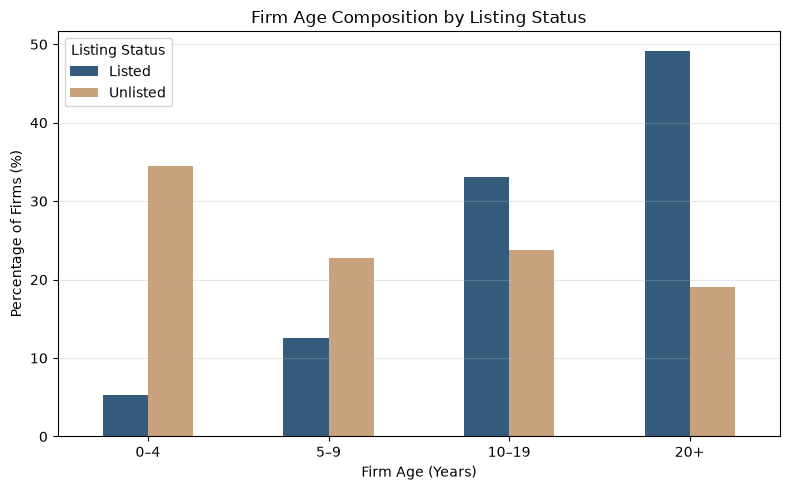

listing_status,Listed,Unlisted
consolidation,,
C1,495,1
C2,1,3085
U1,0,43505
U2,0,1908


In [16]:
# Firm Age Composition

age_table = pd.crosstab(
    df["age_band"],
    df["listing_status"],
    normalize="columns"
) * 100

display(age_table.round(2))

age_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=[COLORS["Listed"], COLORS["Unlisted"]]
)

plt.title("Firm Age Composition by Listing Status")
plt.xlabel("Firm Age (Years)")
plt.ylabel("Percentage of Firms (%)")
plt.xticks(rotation=0)
plt.legend(title="Listing Status")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Consolidation Code Composition

consolidation_table = pd.crosstab(
    df["consolidation"],
    df["listing_status"]
)

display(consolidation_table)

In [17]:
# Broad Consolidation Status

df["consolidation_group"] = (
    df["consolidation"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str[0]
)

df["consolidation_group"] = df[
    "consolidation_group"
].where(
    df["consolidation_group"].isin(["C", "U"])
)

broad_table = pd.crosstab(
    df["consolidation_group"],
    df["listing_status"],
    normalize="columns"
) * 100

display(broad_table.round(2))

listing_status,Listed,Unlisted
consolidation_group,,
C,100.0,6.36
U,0.0,93.64


## Missing values among matching variables

In [18]:
# Missing Matching Variables

matching_variables = [
    "nace2",
    "firm_age",
    "age_band",
    "consolidation_group"
]

missing_matching = (
    df.groupby("listing_status")[matching_variables]
    .apply(lambda x: x.isna().sum())
)

display(missing_matching)

,nace2,firm_age,age_band,consolidation_group
listing_status,,,,
Listed,0,0,0,0
Unlisted,0,1,1,0


# Analysis

## Full-sample KS test

**Null hypothesis:**

$$
H_0: F_L(x) = F_U(x) \quad \text{for all } x
$$

**Alternative hypothesis:**

$$
H_1: F_L(x) \neq F_U(x) \quad \text{for some } x
$$

In [19]:
from scipy import stats

listed = eda_assets.loc[
    eda_assets["listing_status"] == "Listed",
    "log_assets"
].dropna().astype(float)

unlisted = eda_assets.loc[
    eda_assets["listing_status"] == "Unlisted",
    "log_assets"
].dropna().astype(float)

ks = stats.ks_2samp(listed, unlisted)

print(f"KS statistic: {ks.statistic:.3f}")
print(f"P-value: {ks.pvalue:.3g}")

KS statistic: 0.700
P-value: 6.96e-242


In [20]:
# Check the original incorporation-date values

print("Original incorporation dates:")
display(
    df.loc[
        df["listing_status"] == "Listed",
        ["incorporation_date"]
    ].head(20)
)

print("\nMissing incorporation dates:")
print(
    df.groupby("listing_status")["incorporation_date"]
    .apply(lambda x: x.isna().sum())
)

Original incorporation dates:


,incorporation_date
3,1999-08-14 00:00:00
6,2021-08-26 00:00:00
19,1990-01-05 00:00:00
23,1969-02-15 00:00:00
31,1993-05-26 00:00:00
33,1972-01-28 00:00:00
46,1992-01-04 00:00:00
48,1997-08-09 00:00:00
54,1963-04-25 00:00:00
101,1972-12-15 00:00:00



Missing incorporation dates:
listing_status
Listed      0
Unlisted    0
Name: incorporation_date, dtype: int64
